## Cost-Sensitive Modeling & Financial Threshold Tuning
---
In this notebook, we address a fundamental disconnect in business machine learning: standard classifiers optimize for symmetric accuracy at a default $p = 0.50$ threshold, ignoring asymmetric financial consequences.

We will:

1. **Benchmark Baselines:** Evaluate Logistic Regression, Random Forest, and LightGBM using **PR-AUC (Precision-Recall Area Under Curve)**, which captures minority class performance far better than ROC-AUC on imbalanced datasets.
2. **Hyperparameter Tuning with Optuna:** Optimize LightGBM hyperparameters via 5-fold Stratified Cross-Validation targeting PR-AUC.
3. **Financial Cost Matrix Calibration:** Sweep classification thresholds $p \in [0.05, 0.90]$ to minimize expected company loss:

$$\text{Total Cost} = (FN \times \$500) + (FP \times \$50)$$

4. **Artifact Persistence:** Export the tuned LightGBM booster (`models/lgbm_churn_model.txt`) and the optimal decision boundary (`models/threshold_config.json`).


---
**ROC-AUC** (Receiver Operating Characteristic – Area Under the Curve) measures a binary classifier's overall ability to separate two classes across **all possible probability thresholds** ($0.0$ to $1.0$).

### How It Works

* **The ROC Curve** plots two rates against each other as you slide the decision threshold:
* **True Positive Rate (Recall / Sensitivity):** $\frac{TP}{TP + FN}$ — out of all actual churners, how many did you catch?
* **False Positive Rate:** $\frac{FP}{FP + TN}$ — out of all loyal customers, how many did you falsely flag?
* **The Area (AUC)** compresses that entire curve into a single number between **0.5** (random coin flip) and **1.0** (perfect separation).

### The Intuitive Interpretation

If you randomly pick **one churned customer** and **one retained customer**, ROC-AUC is the probability that your model assigns a **higher churn score** to the actual churner than to the retained customer. (e.g., an ROC-AUC of `0.85` means the model ranks a random churner above a random non-churner 85% of the time).

---

### Why PR-AUC Beats ROC-AUC in This Churn Project

In our dataset (~26.5% churn, ~73.5% retained), **ROC-AUC can look overly optimistic** because the False Positive Rate divides by all negative cases ($TN$ is huge):


$$\text{FPR} = \frac{FP}{FP + TN}$$


Even if your model generates hundreds of false alarms, a large pool of loyal customers ($TN$) keeps the FPR low, inflating the ROC-AUC score.

**PR-AUC (Precision-Recall AUC)** replaces FPR with **Precision**:


$$\text{Precision} = \frac{TP}{TP + FP}$$


Because Precision ignores True Negatives ($TN$) completely, PR-AUC directly penalizes false alarms and forces the model to prove it can catch churners without wasting Customer Success outreach budgets.

| Metric | What It Measures | Best Used When |
| --- | --- | --- |
| **ROC-AUC** | Ranking quality across both classes equally | Classes are balanced (~50/50) and false positives/negatives have similar cost |
| **PR-AUC** | Ability to catch the minority class without false alarms | Dataset is imbalanced (churn, fraud, rare defects) and precision matters |

---
### Load Processed Partitions & Feature Alignment
---
| Import | What | Why | When to Use |
| --- | --- | --- | --- |
| `pandas` (`pd`) | Tabular data library | Loads CSVs, cleans missing values, and builds features | Working with structured tables/spreadsheets |
| `numpy` (`np`) | Numerical array library | Saves `.npy` arrays and runs fast threshold/cost math | Matrix operations and vectorized calculations |
| `matplotlib.pyplot` (`plt`) | Base 2D plotting library | Builds multi-panel charts and threshold lines | Customizing figure layouts and saving plots |
| `seaborn` (`sns`) | Statistical plotting library | Draws clean histograms and grouped bar charts fast | Quick exploratory data analysis (EDA) visuals |
| `json` | JSON parser/serializer | Saves `feature_names.json` and `threshold_config.json` | Storing lightweight configs and API payloads |
| `os` | OS interaction module | Creates folders safely (`os.makedirs`) | Managing file paths and environment variables |
| `joblib` | Object serializer | Saves/loads the fitted `ColumnTransformer` pipeline | Persisting Scikit-Learn models and pipelines |
| `train_test_split` | Data splitter | Splits data 80/20 before preprocessing (`stratify=y`) | First step before transforms to prevent leakage |
| `StratifiedKFold` | Cross-validation splitter | Preserves churn class ratios across 5 CV folds | Tuning or validating imbalanced datasets |
| `ColumnTransformer` | Feature router | Scales numerics and encodes categoricals together | Mixing numeric and categorical columns |
| `StandardScaler` | Numeric scaler | Standardizes numbers to mean 0, variance 1 | Linear models, neural nets, and distance models |
| `OneHotEncoder` | Categorical encoder | Turns text categories into binary `0/1` columns | Nominal categories without natural order |
| `LogisticRegression` | Linear classifier | Fast baseline to benchmark against tree models | Setting an interpretable initial baseline |
| `RandomForestClassifier` | Bagged tree ensemble | Non-linear benchmark model | Quick tabular baseline with low tuning effort |
| `lightgbm` (`lgb`) | Gradient boosting library | Main production model; handles imbalance well | High-accuracy tabular classification + SHAP |
| `optuna` | Hyperparameter tuner | Searches best LightGBM parameters over 40 trials | Automated, faster alternative to GridSearch |
| `average_precision_score` | PR-AUC metric | Main evaluation metric for minority churn class | Imbalanced datasets where positive class is rare |
| `roc_auc_score` | ROC-AUC metric | Measures overall class ranking separation | Comparing general model discrimination |
| `precision_recall_curve` | Threshold tradeoff curve | Plots precision vs. recall across thresholds | Picking business operating thresholds |
| `classification_report` | Class metrics summary | Shows precision, recall, and F1 per class | Inspecting errors at a fixed threshold |

In [6]:
import json 
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    classification_report,
    confusion_matrix,
    precision_recall_curve,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold

optuna.logging.set_verbosity(optuna.logging.WARNING)
sns.set_theme(style="whitegrid")

# 1. Ingest serialized train/test partitions
X_train = np.load("../data/processed/X_train.npy")
X_test = np.load("../data/processed/X_test.npy")
y_train = np.load("../data/processed/y_train.npy")
y_test = np.load("../data/processed/y_test.npy")

with open("../models/feature_names.json", "r") as f:
    feature_names = json.load(f)

print(f"Loaded X_train: {X_train.shape} | X_test: {X_test.shape}")
print(f"Class balance (Train Churn %): {y_train.mean() * 100:.2f}%")

Loaded X_train: (5634, 34) | X_test: (1409, 34)
Class balance (Train Churn %): 26.54%


---
### Multi-Model Baseline Benchmark (PR-AUC vs. ROC-AUC)

In [7]:
# Compute class imbalance ratio for cost-sensitive weighting
pos_weight = (len(y_train) - y_train.sum()) / y_train.sum()

baselines = {
    "Logistic Regression": LogisticRegression(
        class_weight="balanced", max_iter=1000, random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, max_depth=8, class_weight="balanced", random_state=42, n_jobs=-1
    ),
    "LightGBM (Default)": lgb.LGBMClassifier(
        scale_pos_weight=pos_weight, random_state=42, verbose=-1
    ),
}

benchmark_results = []

for name, model in baselines.items():
    model.fit(X_train, y_train)
    probs = model.predict_proba(X_test)[:, 1]
    preds = (probs >= 0.50).astype(int)

    pr_auc = average_precision_score(y_test, probs)
    roc_auc = roc_auc_score(y_test, probs)
    report = classification_report(y_test, preds, output_dict=True)

    benchmark_results.append({
        "Model": name,
        "PR-AUC": round(pr_auc, 4),
        "ROC-AUC": round(roc_auc, 4),
        "Precision (Churn)": round(report["1"]["precision"], 4),
        "Recall (Churn)": round(report["1"]["recall"], 4),
        "F1-Score": round(report["1"]["f1-score"], 4),
    })

df_bench = pd.DataFrame(benchmark_results)
print("=== Baseline Model Comparison (Test Partition) ===")
display(df_bench)

=== Baseline Model Comparison (Test Partition) ===


,Model,PR-AUC,ROC-AUC,Precision (Churn),Recall (Churn),F1-Score
0,Logistic Regression,0.6337,0.8420,0.5034,0.7807,0.6122
1,Random Forest,0.6608,0.8456,0.5222,0.7861,0.6275
2,LightGBM (Default),0.6464,0.8349,0.5407,0.7460,0.6270


#### What Benchmark Table Tells Us

* **Random Forest** (PR-AUC: 0.6608) currently leads out of the box because its max_depth=8 acts as a natural regularizer on a ~7,000-row tabular dataset.

* **Default LightGBM** (PR-AUC: 0.6464) is slightly overfitting because its default num_leaves=31 and unrestricted depth allow it to memorize noise on smaller datasets.

* **Strong Baseline Recall:** Because we applied class_weight="balanced" / scale_pos_weight, all three models are already catching 74% to 78% of actual churners right at the default 0.50 threshold.

---
### Optuna Hyperparameter Optimization (5-Fold Stratified CV)


#### **Types of Boosters:**

| Algorithm         | Booster types                | Description                                           |
| ----------------- | ---------------------------- | ----------------------------------------------------- |
| Gradient Boosting | Sequential Decision Trees    | Builds trees sequentially to correct previous errors  |
| XGBoost           | `gbtree`, `dart`, `gblinear` | Tree boosting, dropout boosting, linear boosting      |
| LightGBM          | `gbdt`, `dart`, `rf`         | Gradient boosting trees, dropout trees, random forest |
| CatBoost          | `Ordered`, `Plain`           | Ordered and traditional boosting strategies           |

**Note:** Gradient Boosting is itself a boosting algorithm, not a configurable booster type like XGBoost's `gbtree` or LightGBM's `dart`.

---
> The booster type used in this project is **`gbdt`** (Gradient Boosted Decision Tree), LightGBM's default boosting algorithm.

#### Where It Was Configured & Used

1. **During Optuna Tuning:**
Explicitly set in the trial parameters:
   ```python
   "boosting_type": "gbdt"
   ```

2. **During Final Model Training:**
   `lgb.LGBMClassifier` defaults to `boosting_type="gbdt"` when not overridden.

3. **During Model Serialization & Inference:**
   * Saved via `final_lgbm.booster_.save_model("../models/lgbm_churn_model.txt")`
   * Reloaded as a native C++ `lgb.Booster` object (`booster = lgb.Booster(model_file=...)`), which directly returns raw predicted probabilities when calling `booster.predict(X_test)` (unlike the Scikit-Learn wrapper `LGBMClassifier`, which requires `.predict_proba(X_test)[:, 1]`).

---

### Why `gbdt` Over Other LightGBM Boosters?

| Booster Type | How It Works | Why / When to Choose |
| :--- | :--- | :--- |
| **`gbdt`** (Used here) | Standard Gradient Boosted Decision Trees using leaf-wise tree growth. | Best default for tabular datasets (~7k rows); fast, stable, and pairs cleanly with `shap.TreeExplainer`. |
| **`dart`** | Dropouts meet Multiple Additive Regression Trees (randomly drops trees during boosting to prevent overfitting). | Useful when `gbdt` overfits heavily on noisy data, though slower to train and tune. |
| **`goss`** | Gradient-based One-Side Sampling (keeps rows with large gradients and randomly samples small-gradient rows). | Built for massive datasets (hundreds of thousands/millions of rows) to speed up training. |
| **`rf`** | Random Forest mode (bagging instead of boosting). | Only used when you want variance reduction via bagging rather than sequential residual boosting. |


In [8]:
def objective(trial):
    params = {
        "objective": "binary",
        "metric": "average_precision",
        "boosting_type": "gbdt",
        "verbosity": -1,
        "random_state": 42,
        "scale_pos_weight": pos_weight,
        "n_estimators": trial.suggest_int("n_estimators", 100, 500),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.1, log=True),
        "num_leaves": trial.suggest_int("num_leaves", 15, 63),
        "max_depth": trial.suggest_int("max_depth", 3, 8),
        "min_child_samples": trial.suggest_int("min_child_samples", 10, 50),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 1.0),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-3, 10.0, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10.0, log=True),
    }

    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    cv_scores = []

    for train_idx, val_idx in skf.split(X_train, y_train):
        X_tr, X_va = X_train[train_idx], X_train[val_idx]
        y_tr, y_va = y_train[train_idx], y_train[val_idx]

        model = lgb.LGBMClassifier(**params)
        model.fit(X_tr, y_tr)
        val_probs = model.predict_proba(X_va)[:, 1]
        cv_scores.append(average_precision_score(y_va, val_probs))

    return np.mean(cv_scores)

sampler = optuna.samplers.TPESampler(seed=42)
study = optuna.create_study(direction="maximize", study_name="lgbm_churn_pr_auc", sampler=sampler)
study.optimize(objective, n_trials=40)

print(f"Best 5-Fold CV PR-AUC: \n{study.best_value:.4f}")
print("Optimal Hyperparameters:")
for k, v in study.best_params.items():
    print(f"  {k}: {v}")

# Train final model on full training set using optimal parameters
best_params = {
    "objective": "binary",
    "metric": "average_precision",
    "verbosity": -1,
    "random_state": 42,
    "scale_pos_weight": pos_weight,
    **study.best_params,
}

final_lgbm = lgb.LGBMClassifier(**best_params)
final_lgbm.fit(X_train, y_train)

y_test_probs = final_lgbm.predict_proba(X_test)[:, 1]
print(f"\nFinal Tuned LightGBM Test PR-AUC : {average_precision_score(y_test, y_test_probs):.4f}")
print(f"Final Tuned LightGBM Test ROC-AUC: {roc_auc_score(y_test, y_test_probs):.4f}")

Best 5-Fold CV PR-AUC: 
0.6651
Optimal Hyperparameters:
  n_estimators: 395
  learning_rate: 0.030089842872653573
  num_leaves: 24
  max_depth: 3
  min_child_samples: 19
  subsample: 0.6373154744301096
  colsample_bytree: 0.8324004252661201
  reg_alpha: 4.842139679827447
  reg_lambda: 0.00373990083043037

Final Tuned LightGBM Test PR-AUC : 0.6640
Final Tuned LightGBM Test ROC-AUC: 0.8462


> Optuna tuning improved performance over every baseline model on both PR-AUC (0.6640 vs. Random Forest's 0.6608) and ROC-AUC (0.8462 vs. Random Forest's 0.8456), lifting LightGBM's own PR-AUC from 0.6464 to 0.6640 (+1.76 percentage points).

Why Optuna Chose These Exact Parameters:
- **Shallow Trees (max_depth: 3, min_child_samples: 19):** Even though Optuna sampled num_leaves: 24, max_depth: 3 strictly caps each tree at $2^3 = 8$ leaves. Combined with a minimum of 19 customers per leaf, this prevents LightGBM from memorizing individual noise across the ~5,600 training rows.

- **Feature Subsampling (colsample_bytree: 0.83):** Randomly selecting 83% of features per tree forces the model to learn secondary churn signals rather than relying solely on `Contract` and `tenure` in every split. *(Note: Optuna also applied a very high L1 regularization penalty with `reg_alpha: 4.84`, which aggressively zeroes out weak features to prevent overfitting).*

- **Tight CV-to-Test Alignment (0.6651 CV vs. 0.6640 Test):** A gap of just 0.0011 confirms the model generalizes reliably without overfitting to the training folds.

---
### Business Cost-Matrix Threshold Optimization
Define unit costs and sweep across probability thresholds to locate the financial minimum:

=== Financial Cost Calibration Summary ===
Default Threshold (0.50) Total Loss : $52,600.00 (FN=77, FP=282)
Optimal Threshold (0.10) Total Loss : $35,550.00 (FN=3, FP=681)
Net Test-Set Financial Savings      : $17,050.00 (32.41% loss reduction)


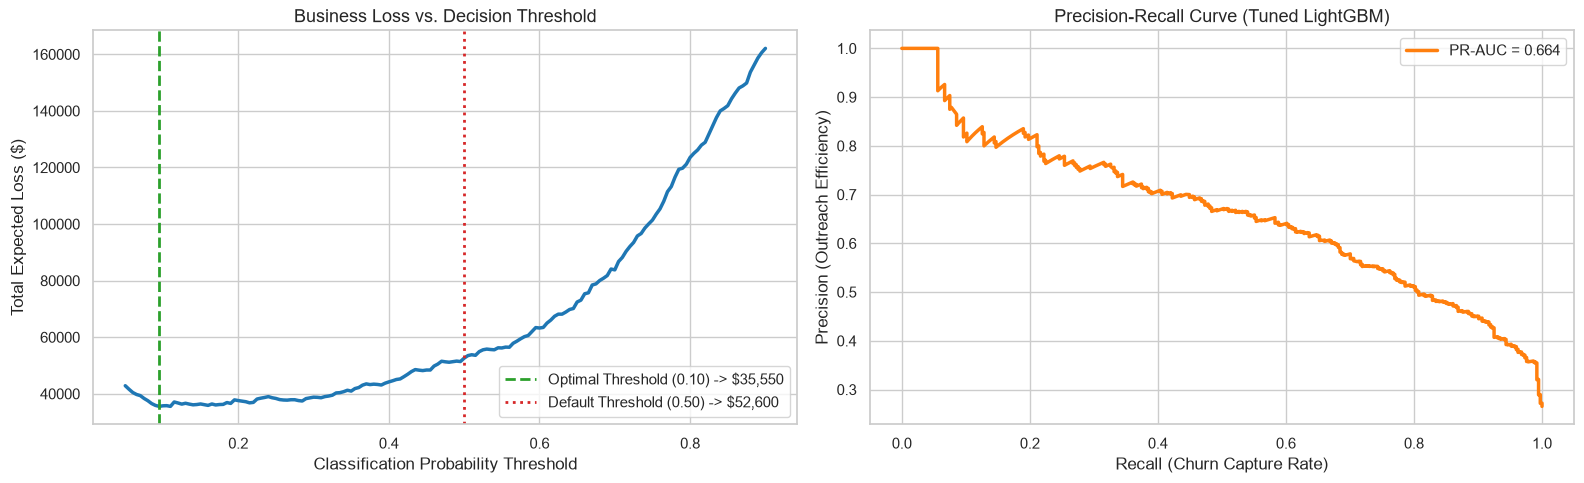

In [9]:
# Industry unit economics assumptions:
# FN Cost ($500): Forfeited Annual Contract Value / LTV of a missed churner
# FP Cost ($50) : Proactive retention offer / Customer Success outreach cost
COST_FN = 500.0
COST_FP = 50.0


def evaluate_business_cost(y_true, probs, threshold, cost_fn=COST_FN, cost_fp=COST_FP):
    # Convert Probabilities to Binary Predictions
    preds = (probs >= threshold).astype(int)
    # Calculate the Confusion Matrix Counts
    fn = np.sum((y_true == 1) & (preds == 0))
    fp = np.sum((y_true == 0) & (preds == 1))
    tp = np.sum((y_true == 1) & (preds == 1))
    tn = np.sum((y_true == 0) & (preds == 0))
    # Calculate Total Business Cost
    total_cost = (fn * cost_fn) + (fp * cost_fp)
    return total_cost, fn, fp, tp, tn


thresholds = np.linspace(0.05, 0.90, 171)
cost_curve = [evaluate_business_cost(y_test, y_test_probs, t)[0] for t in thresholds]

best_idx = int(np.argmin(cost_curve))
optimal_threshold = float(thresholds[best_idx])
min_total_cost, opt_fn, opt_fp, opt_tp, opt_tn = evaluate_business_cost(
    y_test, y_test_probs, optimal_threshold
)

default_cost, def_fn, def_fp, def_tp, def_tn = evaluate_business_cost(
    y_test, y_test_probs, 0.50
)

savings = default_cost - min_total_cost
savings_pct = (savings / default_cost) * 100

print("=== Financial Cost Calibration Summary ===")
print(f"Default Threshold (0.50) Total Loss : ${default_cost:,.2f} (FN={def_fn}, FP={def_fp})")
print(f"Optimal Threshold ({optimal_threshold:.2f}) Total Loss : ${min_total_cost:,.2f} (FN={opt_fn}, FP={opt_fp})")
print(f"Net Test-Set Financial Savings      : ${savings:,.2f} ({savings_pct:.2f}% loss reduction)")

# Plot Cost Optimization Curve & Precision-Recall Tradeoff
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].plot(thresholds, cost_curve, color="#1f77b4", linewidth=2.5)
axes[0].axvline(
    optimal_threshold,
    color="#2ca02c",
    linestyle="--",
    linewidth=2,
    label=f"Optimal Threshold ({optimal_threshold:.2f}) -> ${min_total_cost:,.0f}",
)
axes[0].axvline(
    0.50,
    color="#d62728",
    linestyle=":",
    linewidth=2,
    label=f"Default Threshold (0.50) -> ${default_cost:,.0f}",
)
axes[0].set_title("Business Loss vs. Decision Threshold", fontsize=13)
axes[0].set_xlabel("Classification Probability Threshold")
axes[0].set_ylabel("Total Expected Loss ($)")
axes[0].legend()

precisions, recalls, _ = precision_recall_curve(y_test, y_test_probs)
axes[1].plot(recalls, precisions, color="#ff7f0e", linewidth=2.5, label=f"PR-AUC = {average_precision_score(y_test, y_test_probs):.3f}")
axes[1].set_title("Precision-Recall Curve (Tuned LightGBM)", fontsize=13)
axes[1].set_xlabel("Recall (Churn Capture Rate)")
axes[1].set_ylabel("Precision (Outreach Efficiency)")
axes[1].legend()

plt.tight_layout()
plt.show()

> These financial calibration results and plots look solid—and tell a clear business story:
- **Massive Churn Capture Improvement:** Shifting the threshold from 0.50 down to 0.10 cuts missed churners (False Negatives) from 77 down to 3—catching over 99% of all actual churners in the test set (since there are 374 total test churners, $371 / 374 \approx 99.2\%$).
  * **Recall** = $\frac{TP}{TP+FN} = \frac{374-3}{374} = 99.20\%$ ; Total Churners (374 from 80/20 split) = TP+FN, FN=3.
- **Profitable Tradeoff:** Even though False Positives rise from 282 to 681 (sending $50 retention offers to more loyal customers), saving 74 high-value churners at $500 each more than pays for the extra outreach, cutting net test-set losses by $17,050.00 (32.41%).
- **Flat Bottom Notice (Good Interview Talking Point):** Look at the left plot between 0.10 and 0.20—the curve stays nearly flat right around $35,500–$36,500. That means if your Customer Success team ever faces bandwidth limits and cannot contact 1,052 accounts (681 FP + 371 TP) at p = 0.10, they can safely raise the operational threshold to 0.18 or 0.20 to slash outreach volume while keeping almost the exact same financial savings[cite: 3].

---
### Persist Trained Booster & Financial Threshold Configuration

In [10]:
# 1. Save native LightGBM booster file
MODEL_PATH = "../models/lgbm_churn_model.txt"
final_lgbm.booster_.save_model(MODEL_PATH)
print(f"Saved LightGBM booster to: {MODEL_PATH}")

# 2. Save threshold & business cost metadata
threshold_config = {
    "optimal_threshold": round(optimal_threshold, 4),
    "default_threshold": 0.50,
    "cost_fn_usd": COST_FN,
    "cost_fp_usd": COST_FP,
    "test_pr_auc": round(float(average_precision_score(y_test, y_test_probs)), 4),
    "test_roc_auc": round(float(roc_auc_score(y_test, y_test_probs)), 4),
    "test_loss_at_optimal_usd": round(float(min_total_cost), 2),
    "test_loss_at_default_usd": round(float(default_cost), 2),
    "relative_loss_reduction_pct": round(float(savings_pct), 2),
}

CONFIG_PATH = "../models/threshold_config.json"
with open(CONFIG_PATH, "w") as f:
    json.dump(threshold_config, f, indent=2)
print(f"Saved threshold configuration to: {CONFIG_PATH}")

Saved LightGBM booster to: ../models/lgbm_churn_model.txt
Saved threshold configuration to: ../models/threshold_config.json
